# 03 — Feature Engineering and Feature Selection

## Task 3: regression — synthetic crop-yield dataset

This notebook adapts feature engineering and feature selection to a **continuous numerical target**.

Regression requires a different logic from classification. We are no longer asking whether groups differ. Instead, we ask whether predictors explain continuous variation in `yield_t_ha`, including linear, monotonic, and potentially nonlinear relationships.

## Learning objectives

After completing this notebook, students should be able to:

- construct interpretable agronomic features and interactions;
- understand why squared terms can represent curvature;
- split data before target-dependent feature selection;
- inspect redundancy among original and engineered predictors;
- use Pearson and Spearman association appropriately;
- compare continuous targets across binary categorical predictors;
- use mutual information to screen nonlinear predictor–target relationships;
- use Elastic Net as an embedded regression selector;
- distinguish coefficient shrinkage from causal interpretation;
- export reproducible candidate feature sets for later model comparison.

## 1. Regression-specific perspective

A predictor with low Pearson or Spearman correlation can still be useful if the relationship is curved, thresholded, or interaction-dependent.

Feature engineering can make some of those structures more explicit. For example:

```text
temperature -> temperature + temperature²
rainfall + irrigation -> total supplied water
N + P + K -> total macronutrient input
```

The formulas below are predefined and target-independent. Target-dependent selection is performed only on the training partition.

## 2. Imports and reproducibility

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.multitest import multipletests

from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
from sklearn.linear_model import LogisticRegression, ElasticNetCV
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    KFold,
    GridSearchCV,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")
PASTEL_SEQUENTIAL_CMAP = sns.light_palette("#5B8DB8", as_cmap=True)
PASTEL_DIVERGING_CMAP = sns.diverging_palette(275, 145, s=45, l=75, center="light", as_cmap=True)

## 3. Project paths

In [2]:
def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the repository root. Run the notebook from inside the project."
    )

PROJECT_ROOT = find_project_root(Path.cwd())

PROCESSED_DIR = PROJECT_ROOT / "data" / "synthetic_crop_yield" / "processed_data"
PROCESSED_DATA_PATH = PROCESSED_DIR / "synthetic_crop_yield_1200_processed.csv"
PREPROCESSING_REPORT_PATH = PROCESSED_DIR / "preprocessing_report.json"

FEATURE_DATA_DIR = PROJECT_ROOT / "data" / "synthetic_crop_yield" / "feature_data"
RESULTS_DIR = PROJECT_ROOT / "results" / "synthetic_crop_yield" / "feature_engineering_selection"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"

for directory in [FEATURE_DATA_DIR, FIGURES_DIR, TABLES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Results:", RESULTS_DIR.relative_to(PROJECT_ROOT))

Project root: /home/david/Desktop/depto_computacion/ml_2026/demos_machine_learning_2026
Results: results/synthetic_crop_yield/feature_engineering_selection


## 4. Load the processed dataset and analytical roles

In [3]:
if not PROCESSED_DATA_PATH.exists() or not PREPROCESSING_REPORT_PATH.exists():
    raise FileNotFoundError(
        "Processed data are missing. Run task3_crop_yield/01_tabular_data_preprocessing.ipynb first."
    )

df = pd.read_csv(PROCESSED_DATA_PATH)
with PREPROCESSING_REPORT_PATH.open("r", encoding="utf-8") as file:
    preprocessing_report = json.load(file)

ID_COLUMN = preprocessing_report["identifier_column"]
TARGET_COLUMN = preprocessing_report["target_column"]
ORIGINAL_NUMERICAL = list(preprocessing_report["numerical_columns"])
CATEGORICAL_COLUMNS = list(preprocessing_report["categorical_columns"])

print("Shape:", df.shape)
display(df[TARGET_COLUMN].describe().to_frame("yield_t_ha"))

Shape: (1200, 21)


,yield_t_ha
count,1200.000000
mean,4.281533
std,1.470083
min,0.700000
25%,3.280000
50%,4.430000
75%,5.320000
max,8.110000


## 5. Train/test split

Regression does not use class stratification. The random seed fixes the partition for reproducibility.

The held-out test target is not used for feature screening or regularization tuning.

In [4]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

split_summary = pd.DataFrame({
    "partition": ["train", "test"],
    "n": [len(train_df), len(test_df)],
    "target_mean": [train_df[TARGET_COLUMN].mean(), test_df[TARGET_COLUMN].mean()],
    "target_std": [train_df[TARGET_COLUMN].std(), test_df[TARGET_COLUMN].std()],
})
display(split_summary.round(3))

split_assignments = pd.concat([
    train_df[[ID_COLUMN]].assign(split="train"),
    test_df[[ID_COLUMN]].assign(split="test"),
], ignore_index=True)
split_assignments.to_csv(TABLES_DIR / "train_test_split.csv", index=False)

,partition,n,target_mean,target_std
0,train,960,4.268,1.485
1,test,240,4.334,1.410


# Part I — Feature engineering

## 6. Agronomic combinations, curvature, and interactions

The engineered variables illustrate three common strategies:

1. **aggregation**, such as total water or total NPK input;
2. **ratios**, such as nitrogen-to-phosphorus balance;
3. **nonlinear and interaction terms**, such as squared temperature or water supplied during drought conditions.

These features should be interpreted as candidate representations, not guaranteed improvements.

In [5]:
def engineer_crop_features(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()

    out["total_water_mm"] = out["season_rainfall_mm"] + out["irrigation_mm"]
    out["npk_total_kg_ha"] = (
        out["nitrogen_kg_ha"] + out["phosphorus_kg_ha"] + out["potassium_kg_ha"]
    )
    out["n_to_p_ratio"] = out["nitrogen_kg_ha"] / out["phosphorus_kg_ha"].replace(0, np.nan)

    out["mean_temperature_c_squared"] = out["mean_temperature_c"] ** 2
    out["soil_ph_squared"] = out["soil_ph"] ** 2
    out["soil_moisture_pct_squared"] = out["soil_moisture_pct"] ** 2

    out["water_x_drought"] = out["total_water_mm"] * out["drought_event"]
    out["pest_x_fungicide"] = out["pest_pressure_score_0_10"] * out["fungicide_used"]
    out["organic_matter_x_moisture"] = (
        out["soil_organic_matter_pct"] * out["soil_moisture_pct"]
    )
    return out


train_eng = engineer_crop_features(train_df)
test_eng = engineer_crop_features(test_df)
full_eng = engineer_crop_features(df)

ENGINEERED_NUMERICAL = [
    "total_water_mm",
    "npk_total_kg_ha",
    "n_to_p_ratio",
    "mean_temperature_c_squared",
    "soil_ph_squared",
    "soil_moisture_pct_squared",
    "water_x_drought",
    "pest_x_fungicide",
    "organic_matter_x_moisture",
]
NUMERICAL_COLUMNS = ORIGINAL_NUMERICAL + ENGINEERED_NUMERICAL
FEATURE_COLUMNS = NUMERICAL_COLUMNS + CATEGORICAL_COLUMNS

if train_eng[FEATURE_COLUMNS].isna().sum().sum() > 0:
    raise ValueError("Engineered features contain missing values. Check ratio denominators.")
if not np.isfinite(train_eng[FEATURE_COLUMNS].to_numpy(dtype=float)).all():
    raise ValueError("Engineered features contain non-finite values.")

engineering_table = pd.DataFrame({
    "engineered_feature": ENGINEERED_NUMERICAL,
    "strategy": [
        "aggregation", "aggregation", "ratio",
        "curvature", "curvature", "curvature",
        "interaction", "interaction", "interaction",
    ],
})
display(engineering_table)

,engineered_feature,strategy
0,total_water_mm,aggregation
1,npk_total_kg_ha,aggregation
2,n_to_p_ratio,ratio
3,mean_temperature_c_squared,curvature
4,soil_ph_squared,curvature
5,soil_moisture_pct_squared,curvature
6,water_x_drought,interaction
7,pest_x_fungicide,interaction
8,organic_matter_x_moisture,interaction


## 7. Export the engineered candidate dataset

In [6]:
ENGINEERED_DATA_PATH = FEATURE_DATA_DIR / "synthetic_crop_yield_engineered.csv"
full_eng.to_csv(ENGINEERED_DATA_PATH, index=False)
print("Exported:", ENGINEERED_DATA_PATH.relative_to(PROJECT_ROOT))
print("Shape:", full_eng.shape)

Exported: data/synthetic_crop_yield/feature_data/synthetic_crop_yield_engineered.csv
Shape: (1200, 30)


# Part II — Unsupervised screening

## 8. Constant, near-constant, and redundant predictors

Squared terms and aggregates are expected to be correlated with their source variables. The purpose of this section is to make that trade-off visible rather than automatically delete engineered features.

In [7]:
constant_numerical = [c for c in NUMERICAL_COLUMNS if train_eng[c].nunique(dropna=False) <= 1]

categorical_prevalence = train_eng[CATEGORICAL_COLUMNS].mean().rename("prevalence").to_frame()
categorical_prevalence["near_constant"] = (
    (categorical_prevalence["prevalence"] < 0.01)
    | (categorical_prevalence["prevalence"] > 0.99)
)

print("Constant numerical features:", constant_numerical or "None")
display(categorical_prevalence.sort_values("prevalence"))

Constant numerical features: None


,prevalence,near_constant
drought_event,0.213542,False
organic_management,0.237500,False
previous_legume_crop,0.294792,False
irrigation_system_drip,0.373958,False
fungicide_used,0.460417,False
cultivar_improved,0.580208,False


In [8]:
def benjamini_hochberg(p_values):
    p_values = np.asarray(p_values, dtype=float)
    valid = np.isfinite(p_values)
    adjusted = np.full(len(p_values), np.nan, dtype=float)
    rejected = np.full(len(p_values), False, dtype=bool)
    if valid.any():
        rejected_valid, adjusted_valid, _, _ = multipletests(
            p_values[valid], alpha=0.05, method="fdr_bh"
        )
        adjusted[valid] = adjusted_valid
        rejected[valid] = rejected_valid
    return adjusted, rejected


def cramers_v(table):
    chi2, _, _, _ = stats.chi2_contingency(table, correction=False)
    n = table.to_numpy().sum()
    if n == 0:
        return np.nan
    r, k = table.shape
    denominator = min(k - 1, r - 1)
    if denominator <= 0:
        return 0.0
    return np.sqrt((chi2 / n) / denominator)


def hedges_g(x0, x1):
    x0 = np.asarray(x0, dtype=float)
    x1 = np.asarray(x1, dtype=float)
    x0 = x0[np.isfinite(x0)]
    x1 = x1[np.isfinite(x1)]
    n0, n1 = len(x0), len(x1)
    if n0 < 2 or n1 < 2:
        return np.nan
    pooled_var = ((n0 - 1) * x0.var(ddof=1) + (n1 - 1) * x1.var(ddof=1)) / (n0 + n1 - 2)
    if pooled_var <= 0:
        return 0.0
    d = (x1.mean() - x0.mean()) / np.sqrt(pooled_var)
    correction = 1 - 3 / (4 * (n0 + n1) - 9)
    return correction * d


def cliffs_delta_from_u(u_statistic, n0, n1):
    if n0 == 0 or n1 == 0:
        return np.nan
    return (2 * u_statistic) / (n0 * n1) - 1


def correlation_pairs(corr, threshold=0.90):
    rows = []
    columns = list(corr.columns)
    for i, left in enumerate(columns):
        for right in columns[i + 1:]:
            value = corr.loc[left, right]
            if np.isfinite(value) and abs(value) >= threshold:
                rows.append({
                    "feature_a": left,
                    "feature_b": right,
                    "spearman_rho": value,
                    "abs_spearman_rho": abs(value),
                })
    if not rows:
        return pd.DataFrame(columns=["feature_a", "feature_b", "spearman_rho", "abs_spearman_rho"])
    return pd.DataFrame(rows).sort_values("abs_spearman_rho", ascending=False).reset_index(drop=True)


def plot_horizontal_ranking(frame, value_col, label_col, title, xlabel, path, top_n=20):
    plot_df = frame.sort_values(value_col, ascending=False).head(top_n).copy()
    plt.figure(figsize=(9, max(4.5, 0.34 * len(plot_df))))
    sns.barplot(data=plot_df, y=label_col, x=value_col, color=sns.color_palette("pastel")[0])
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("")
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()

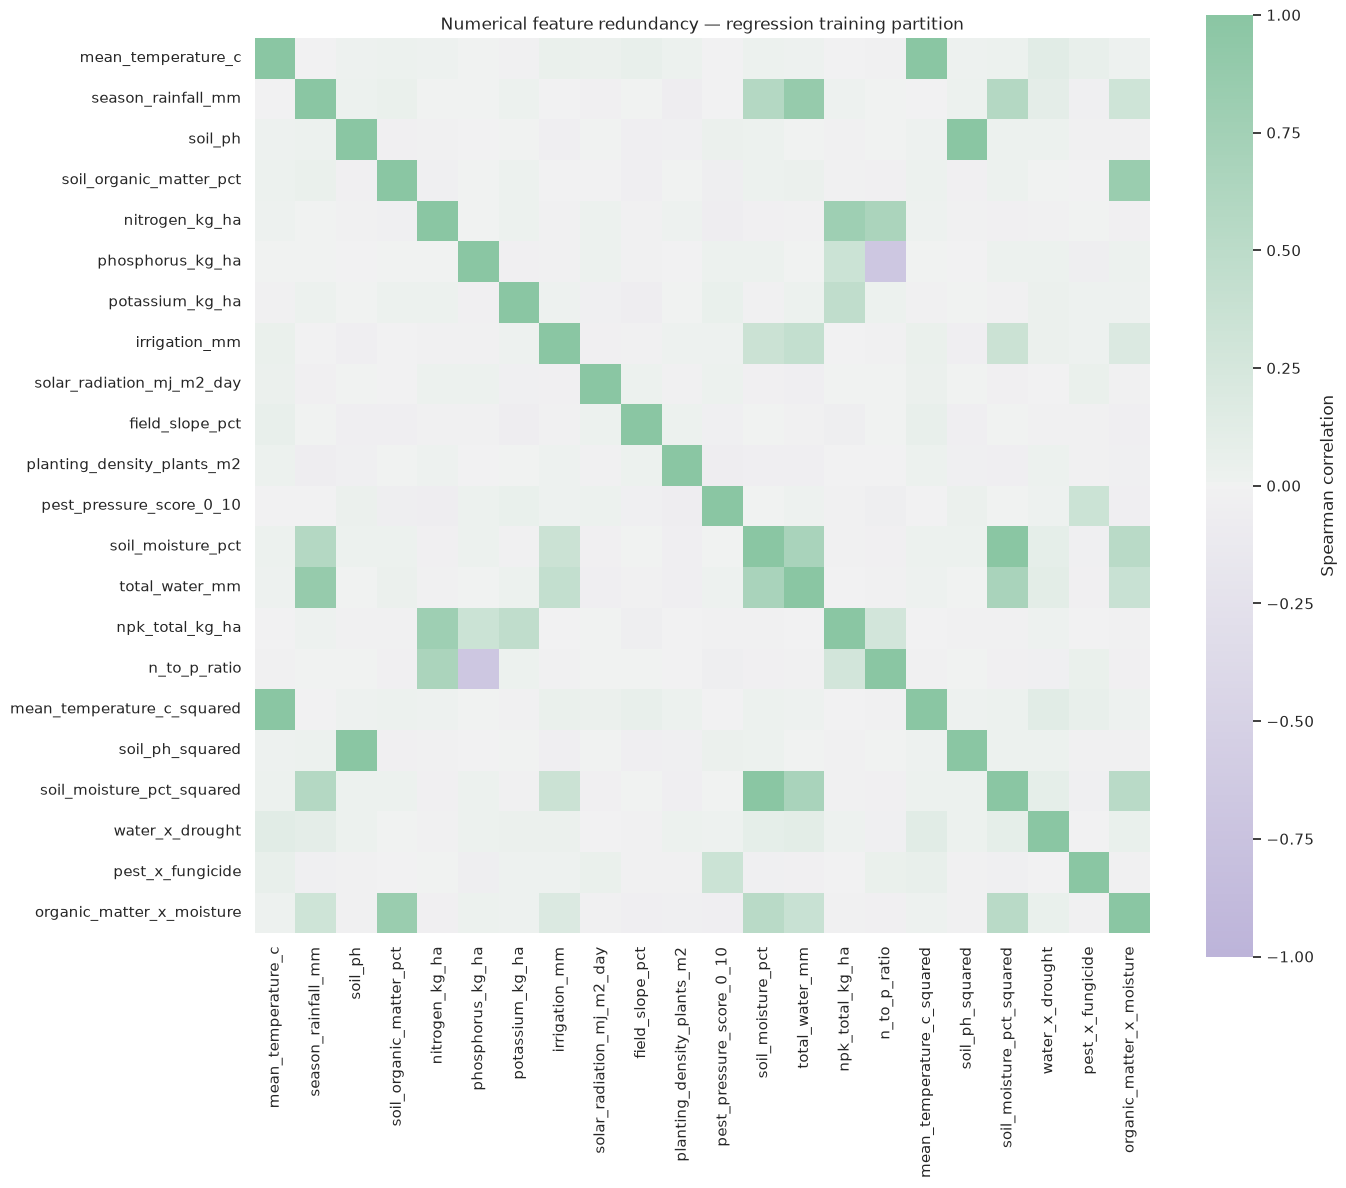

,feature_a,feature_b,spearman_rho,abs_spearman_rho
0,mean_temperature_c,mean_temperature_c_squared,1.0,1.0
1,soil_ph,soil_ph_squared,1.0,1.0
2,soil_moisture_pct,soil_moisture_pct_squared,1.0,1.0


In [9]:
spearman_corr = train_eng[NUMERICAL_COLUMNS].corr(method="spearman")
redundant_pairs = correlation_pairs(spearman_corr, threshold=0.90)

plt.figure(figsize=(14, 12))
sns.heatmap(
    spearman_corr,
    cmap=PASTEL_DIVERGING_CMAP,
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    cbar_kws={"label": "Spearman correlation"},
)
plt.title("Numerical feature redundancy — regression training partition")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_numerical_redundancy_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

display(redundant_pairs.head(25))
redundant_pairs.to_csv(TABLES_DIR / "numerical_redundant_pairs.csv", index=False)

# Part III — Regression filter methods

## 9. Numerical predictors versus a continuous target

We report both Pearson and Spearman association:

- **Pearson** emphasizes linear association;
- **Spearman** emphasizes monotonic association.

A feature is flagged by the illustrative filter if its Spearman association survives FDR correction and has `|rho| >= 0.10`.

This filter can miss U-shaped relationships, which is one reason we also use mutual information and engineered curvature terms.

,feature,pearson_r,pearson_p,spearman_rho,spearman_p,abs_spearman_rho,spearman_q,fdr_reject,filter_selected
0,water_x_drought,-0.2346,0.0000,-0.2582,0.0000,0.2582,0.0000,True,True
1,pest_pressure_score_0_10,-0.2557,0.0000,-0.2493,0.0000,0.2493,0.0000,True,True
2,soil_organic_matter_pct,0.2388,0.0000,0.2013,0.0000,0.2013,0.0000,True,True
3,season_rainfall_mm,0.1089,0.0007,0.1563,0.0000,0.1563,0.0000,True,True
4,organic_matter_x_moisture,0.1442,0.0000,0.1480,0.0000,0.1480,0.0000,True,True
5,solar_radiation_mj_m2_day,0.1388,0.0000,0.1354,0.0000,0.1354,0.0001,True,True
6,nitrogen_kg_ha,0.1364,0.0000,0.1311,0.0000,0.1311,0.0001,True,True
7,npk_total_kg_ha,0.1208,0.0002,0.1188,0.0002,0.1188,0.0006,True,True
8,field_slope_pct,-0.1252,0.0001,-0.1078,0.0008,0.1078,0.0020,True,True
9,n_to_p_ratio,0.0818,0.0112,0.1025,0.0015,0.1025,0.0032,True,True


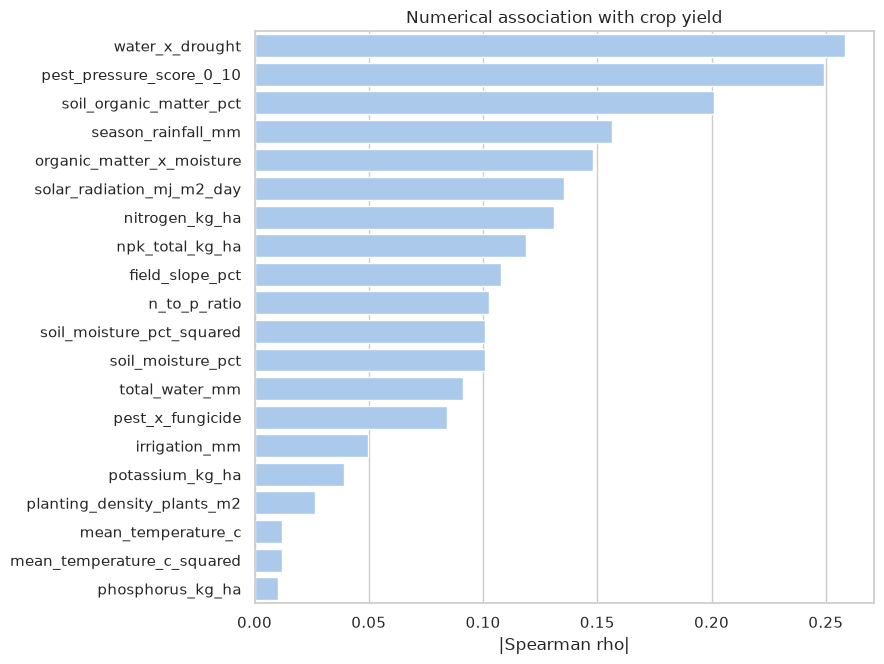

In [10]:
numerical_rows = []
for feature in NUMERICAL_COLUMNS:
    x = train_eng[feature].to_numpy(dtype=float)
    y = train_eng[TARGET_COLUMN].to_numpy(dtype=float)

    pearson = stats.pearsonr(x, y)
    spearman = stats.spearmanr(x, y)

    numerical_rows.append({
        "feature": feature,
        "pearson_r": pearson.statistic,
        "pearson_p": pearson.pvalue,
        "spearman_rho": spearman.statistic,
        "spearman_p": spearman.pvalue,
        "abs_spearman_rho": abs(spearman.statistic),
    })

numerical_filter = pd.DataFrame(numerical_rows)
numerical_filter["spearman_q"], numerical_filter["fdr_reject"] = benjamini_hochberg(
    numerical_filter["spearman_p"]
)
numerical_filter["filter_selected"] = (
    numerical_filter["fdr_reject"]
    & (numerical_filter["abs_spearman_rho"] >= 0.10)
)
numerical_filter = numerical_filter.sort_values("abs_spearman_rho", ascending=False).reset_index(drop=True)

display(numerical_filter.round(4))
numerical_filter.to_csv(TABLES_DIR / "numerical_filter_selection.csv", index=False)
plot_horizontal_ranking(
    numerical_filter,
    "abs_spearman_rho",
    "feature",
    "Numerical association with crop yield",
    "|Spearman rho|",
    FIGURES_DIR / "02_numerical_target_associations.png",
)

## 10. Binary categorical predictors versus a continuous target

For each binary predictor we compare the target distribution between `0` and `1` using Welch's t-test and Mann–Whitney U. Hedges' g provides an effect-size estimate.

This is the regression analogue of asking whether a categorical management condition is associated with a shift in yield.

,feature,mean_target_0,mean_target_1,welch_p,mann_whitney_p,hedges_g,abs_hedges_g,mann_whitney_q,fdr_reject,filter_selected
0,drought_event,4.4707,3.5233,0.0000,0.0000,-0.6600,0.6600,0.0000,True,True
1,cultivar_improved,3.9370,4.5082,0.0000,0.0000,0.3912,0.3912,0.0000,True,True
2,organic_management,4.3108,4.1321,0.0993,0.0530,-0.1203,0.1203,0.1060,False,False
3,irrigation_system_drip,4.2139,4.3597,0.1530,0.0906,0.0981,0.0981,0.1359,False,False
4,previous_legume_crop,4.2395,4.3375,0.3624,0.4100,0.0659,0.0659,0.4100,False,False
5,fungicide_used,4.2977,4.2341,0.5080,0.3308,-0.0428,0.0428,0.3969,False,False


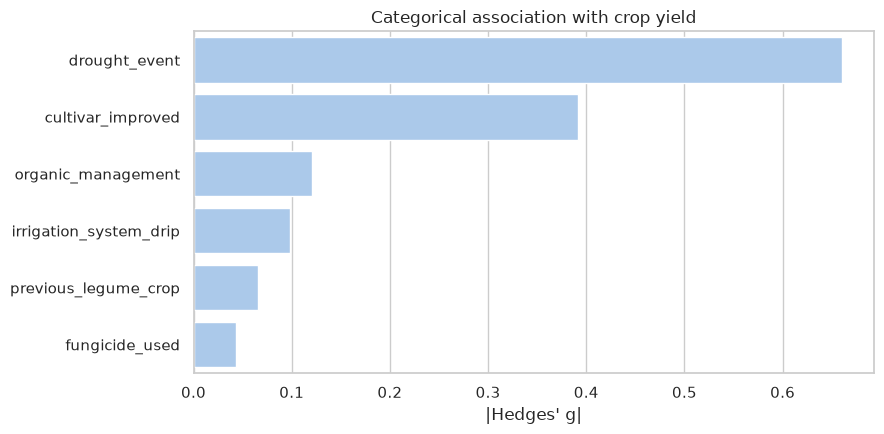

In [11]:
categorical_rows = []
for feature in CATEGORICAL_COLUMNS:
    y0 = train_eng.loc[train_eng[feature] == 0, TARGET_COLUMN].dropna()
    y1 = train_eng.loc[train_eng[feature] == 1, TARGET_COLUMN].dropna()

    welch = stats.ttest_ind(y0, y1, equal_var=False, nan_policy="omit")
    mann = stats.mannwhitneyu(y0, y1, alternative="two-sided")

    categorical_rows.append({
        "feature": feature,
        "mean_target_0": y0.mean(),
        "mean_target_1": y1.mean(),
        "welch_p": welch.pvalue,
        "mann_whitney_p": mann.pvalue,
        "hedges_g": hedges_g(y0, y1),
        "abs_hedges_g": abs(hedges_g(y0, y1)),
    })

categorical_filter = pd.DataFrame(categorical_rows)
categorical_filter["mann_whitney_q"], categorical_filter["fdr_reject"] = benjamini_hochberg(
    categorical_filter["mann_whitney_p"]
)
categorical_filter["filter_selected"] = (
    categorical_filter["fdr_reject"]
    & (categorical_filter["abs_hedges_g"] >= 0.20)
)
categorical_filter = categorical_filter.sort_values("abs_hedges_g", ascending=False).reset_index(drop=True)

display(categorical_filter.round(4))
categorical_filter.to_csv(TABLES_DIR / "categorical_filter_selection.csv", index=False)
plot_horizontal_ranking(
    categorical_filter,
    "abs_hedges_g",
    "feature",
    "Categorical association with crop yield",
    "|Hedges' g|",
    FIGURES_DIR / "03_categorical_target_effect_sizes.png",
)

# Part IV — Mutual information for regression

## 11. Nonlinear dependence

`mutual_info_regression` can identify nonlinear dependence that correlation may miss. Binary predictors are marked as discrete; numerical predictors are treated as continuous.

,feature,mutual_information,top_quartile_positive_mi
0,mean_temperature_c_squared,0.2051,True
1,mean_temperature_c,0.2031,True
2,season_rainfall_mm,0.0843,True
3,soil_moisture_pct,0.0836,True
4,soil_moisture_pct_squared,0.0752,True
5,organic_matter_x_moisture,0.0716,True
6,total_water_mm,0.0692,False
7,water_x_drought,0.0579,False
8,drought_event,0.0524,False
9,soil_organic_matter_pct,0.0352,False


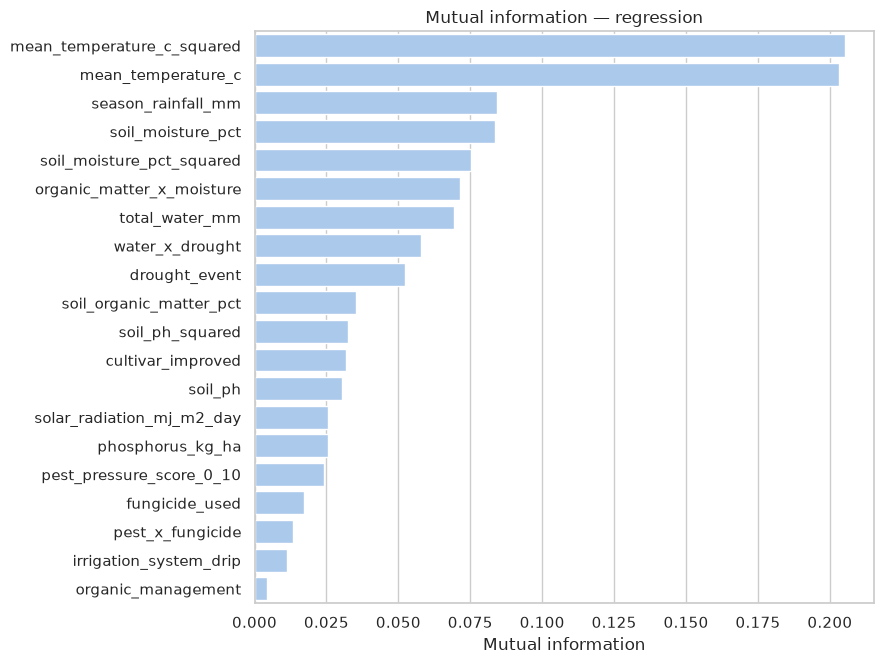

In [12]:
X_train = train_eng[FEATURE_COLUMNS]
y_train = train_eng[TARGET_COLUMN]

discrete_mask = np.array([feature in CATEGORICAL_COLUMNS for feature in FEATURE_COLUMNS])
mi_values = mutual_info_regression(
    X_train,
    y_train,
    discrete_features=discrete_mask,
    random_state=RANDOM_STATE,
)

mutual_information = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "mutual_information": mi_values,
}).sort_values("mutual_information", ascending=False).reset_index(drop=True)

positive_mi = mutual_information.loc[mutual_information["mutual_information"] > 0, "mutual_information"]
mi_threshold = positive_mi.quantile(0.75) if len(positive_mi) else np.inf
mutual_information["top_quartile_positive_mi"] = (
    mutual_information["mutual_information"] >= mi_threshold
)

display(mutual_information.round(4))
mutual_information.to_csv(TABLES_DIR / "mutual_information.csv", index=False)
plot_horizontal_ranking(
    mutual_information,
    "mutual_information",
    "feature",
    "Mutual information — regression",
    "Mutual information",
    FIGURES_DIR / "04_mutual_information.png",
)

# Part V — Embedded selection with Elastic Net

## 12. Why Elastic Net?

Elastic Net combines L1 and L2 regularization. This is useful when correlated predictors exist because pure L1 selection may choose one member of a correlated group somewhat arbitrarily.

Standardization and regularization tuning are performed inside the training workflow. The test partition remains untouched.

Selected alpha: 0.001
Selected l1_ratio: 1.0


,feature,coefficient,abs_coefficient,embedded_selected
0,mean_temperature_c,6.2462,6.2462,True
1,mean_temperature_c_squared,-6.2234,6.2234,True
2,soil_moisture_pct_squared,-4.2819,4.2819,True
3,soil_moisture_pct,3.7475,3.7475,True
4,soil_ph,2.2942,2.2942,True
5,soil_ph_squared,-2.2467,2.2467,True
6,total_water_mm,0.3608,0.3608,True
7,soil_organic_matter_pct,0.3395,0.3395,True
8,drought_event,-0.3384,0.3384,True
9,pest_pressure_score_0_10,-0.3358,0.3358,True


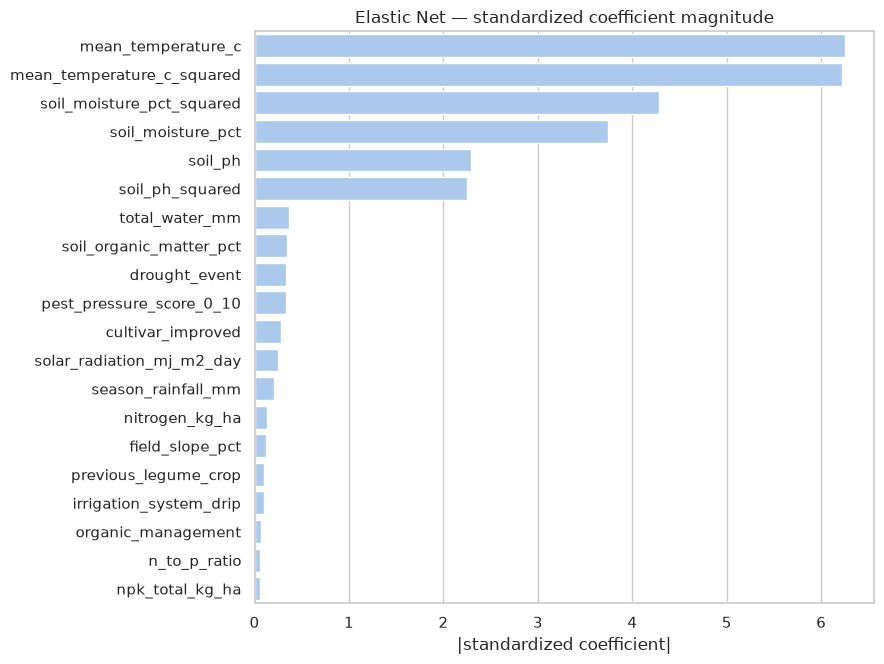

In [13]:
regression_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

elastic_pipeline = Pipeline([
    ("scale", StandardScaler()),
    (
        "model",
        ElasticNetCV(
            l1_ratio=[0.10, 0.50, 0.90, 1.00],
            alphas=np.logspace(-3, 1, 60),
            cv=regression_cv,
            max_iter=20000,
            random_state=RANDOM_STATE,
        ),
    ),
])

elastic_pipeline.fit(X_train, y_train)
elastic_model = elastic_pipeline.named_steps["model"]

elastic_table = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "coefficient": elastic_model.coef_,
    "abs_coefficient": np.abs(elastic_model.coef_),
})
elastic_table["embedded_selected"] = elastic_table["abs_coefficient"] > 1e-8
elastic_table = elastic_table.sort_values("abs_coefficient", ascending=False).reset_index(drop=True)

print("Selected alpha:", round(float(elastic_model.alpha_), 6))
print("Selected l1_ratio:", float(elastic_model.l1_ratio_))
display(elastic_table.round(4))
elastic_table.to_csv(TABLES_DIR / "elastic_net_coefficients.csv", index=False)
plot_horizontal_ranking(
    elastic_table,
    "abs_coefficient",
    "feature",
    "Elastic Net — standardized coefficient magnitude",
    "|standardized coefficient|",
    FIGURES_DIR / "05_elastic_net_coefficients.png",
)

## 13. Inspect engineered nonlinear terms

Squared terms are intentionally redundant with their source variables. Their value is not that they are independent measurements, but that a linear model can use them to express curvature.

This small table lets us compare correlation and mutual-information evidence for the original variables and their engineered nonlinear forms.

In [14]:
nonlinear_pairs = [
    ("mean_temperature_c", "mean_temperature_c_squared"),
    ("soil_ph", "soil_ph_squared"),
    ("soil_moisture_pct", "soil_moisture_pct_squared"),
]

nonlinear_rows = []
mi_lookup = mutual_information.set_index("feature")["mutual_information"]
num_lookup = numerical_filter.set_index("feature")
for original, squared in nonlinear_pairs:
    for feature, representation in [(original, "original"), (squared, "squared")]:
        nonlinear_rows.append({
            "concept": original,
            "representation": representation,
            "feature": feature,
            "pearson_r": num_lookup.loc[feature, "pearson_r"],
            "spearman_rho": num_lookup.loc[feature, "spearman_rho"],
            "mutual_information": mi_lookup.loc[feature],
            "elastic_abs_coefficient": elastic_table.set_index("feature").loc[feature, "abs_coefficient"],
        })

nonlinear_comparison = pd.DataFrame(nonlinear_rows)
display(nonlinear_comparison.round(4))
nonlinear_comparison.to_csv(TABLES_DIR / "nonlinear_feature_comparison.csv", index=False)

,concept,representation,feature,pearson_r,spearman_rho,mutual_information,elastic_abs_coefficient
0,mean_temperature_c,original,mean_temperature_c,0.0175,0.0120,0.2031,6.2462
1,mean_temperature_c,squared,mean_temperature_c_squared,-0.0412,0.0120,0.2051,6.2234
2,soil_ph,original,soil_ph,0.0094,-0.0002,0.0304,2.2942
3,soil_ph,squared,soil_ph_squared,0.0008,-0.0002,0.0325,2.2467
4,soil_moisture_pct,original,soil_moisture_pct,-0.1193,-0.1008,0.0836,3.7475
5,soil_moisture_pct,squared,soil_moisture_pct_squared,-0.1741,-0.1008,0.0752,4.2819


# Part VI — Consensus candidate features

## 14. Combine complementary evidence

The regression consensus uses:

1. type-aware filter evidence;
2. top-quartile positive mutual information;
3. nonzero Elastic Net coefficient.

A feature with at least two votes enters the illustrative consensus set.

In [15]:
filter_selected = set(
    numerical_filter.loc[numerical_filter["filter_selected"], "feature"]
).union(
    categorical_filter.loc[categorical_filter["filter_selected"], "feature"]
)
mi_selected = set(
    mutual_information.loc[mutual_information["top_quartile_positive_mi"], "feature"]
)
embedded_selected = set(
    elastic_table.loc[elastic_table["embedded_selected"], "feature"]
)

selection_summary = pd.DataFrame({"feature": FEATURE_COLUMNS})
selection_summary["filter_selected"] = selection_summary["feature"].isin(filter_selected)
selection_summary["mi_top_quartile"] = selection_summary["feature"].isin(mi_selected)
selection_summary["elastic_net_selected"] = selection_summary["feature"].isin(embedded_selected)
selection_summary["selection_votes"] = selection_summary[
    ["filter_selected", "mi_top_quartile", "elastic_net_selected"]
].sum(axis=1)
selection_summary["consensus_selected"] = selection_summary["selection_votes"] >= 2
selection_summary = selection_summary.sort_values(
    ["selection_votes", "feature"], ascending=[False, True]
).reset_index(drop=True)

CONSENSUS_FEATURES = selection_summary.loc[
    selection_summary["consensus_selected"], "feature"
].tolist()

display(selection_summary)
print(f"All candidate predictors: {len(FEATURE_COLUMNS)}")
print(f"Consensus candidate predictors: {len(CONSENSUS_FEATURES)}")
print(CONSENSUS_FEATURES)
selection_summary.to_csv(TABLES_DIR / "feature_selection_summary.csv", index=False)

,feature,filter_selected,mi_top_quartile,elastic_net_selected,selection_votes,consensus_selected
0,season_rainfall_mm,True,True,True,3,True
1,soil_moisture_pct,True,True,True,3,True
2,soil_moisture_pct_squared,True,True,True,3,True
3,cultivar_improved,True,False,True,2,True
4,drought_event,True,False,True,2,True
5,field_slope_pct,True,False,True,2,True
6,mean_temperature_c,False,True,True,2,True
7,mean_temperature_c_squared,False,True,True,2,True
8,n_to_p_ratio,True,False,True,2,True
9,nitrogen_kg_ha,True,False,True,2,True


All candidate predictors: 28
Consensus candidate predictors: 16
['season_rainfall_mm', 'soil_moisture_pct', 'soil_moisture_pct_squared', 'cultivar_improved', 'drought_event', 'field_slope_pct', 'mean_temperature_c', 'mean_temperature_c_squared', 'n_to_p_ratio', 'nitrogen_kg_ha', 'npk_total_kg_ha', 'organic_matter_x_moisture', 'pest_pressure_score_0_10', 'soil_organic_matter_pct', 'solar_radiation_mj_m2_day', 'water_x_drought']


## 15. Export the feature manifest

In [16]:
manifest = {
    "dataset": "synthetic_crop_yield",
    "task_type": "regression",
    "target": TARGET_COLUMN,
    "random_state": RANDOM_STATE,
    "train_size": len(train_eng),
    "test_size": len(test_eng),
    "original_numerical_features": ORIGINAL_NUMERICAL,
    "engineered_numerical_features": ENGINEERED_NUMERICAL,
    "categorical_features": CATEGORICAL_COLUMNS,
    "all_candidate_features": FEATURE_COLUMNS,
    "filter_selected_features": sorted(filter_selected),
    "mutual_information_top_quartile_features": sorted(mi_selected),
    "elastic_net_selected_features": sorted(embedded_selected),
    "consensus_features": CONSENSUS_FEATURES,
    "note": (
        "Supervised selection was learned on the training partition only. "
        "Formal model benchmarking should refit selection inside each training fold."
    ),
}
with (RESULTS_DIR / "feature_selection_manifest.json").open("w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2)

print("Feature manifest exported.")

Feature manifest exported.


# Final interpretation

Regression feature selection must account for more than simple correlation. A predictor can matter through curvature, thresholds, or interactions, which is why this notebook combines:

```text
correlation-based evidence
+ group comparisons for categorical predictors
+ mutual information
+ regularized multivariable selection
```

The engineered and selected feature sets are now ready for formal comparison during model development. The held-out test set has not been used to decide which predictors to retain.